# 🧠 PyTorch 첫걸음 — 손으로 풀었던 XOR, PyTorch로 다시 풀기

**건축공학딥러닝프로그래밍 (2026-2) · 11차시 Part 1 · 실습 노트북 (완성본)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_DL-AE/blob/main/L11/L11_xor_practice.ipynb) ← **실습본**(빈칸 채우기) &nbsp;&nbsp;[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_DL-AE/blob/main/L11/L11_xor_complete.ipynb) ← **완성본**(정답·실행결과 포함)

> 지난 10차시에 칠판에서 **손으로** 계산했던 XOR 신경망(입력 2 – 은닉 2 – 출력 1)을 기억하나요?
> 오늘은 같은 신경망을 PyTorch로 만들어 **같은 초기 가중치 · 같은 학습률(0.5)** 로 1만 에포크(업데이트 4만 번) 학습시킵니다.
> 마지막에 나온 가중치가 강의노트 그림과 **똑같은지(±0.01 이내)** 직접 확인해 봅시다.

## 📌 강의 중점
- 10차시 손계산 XOR 신경망(2-2-1)을 PyTorch로 **그대로 재현**
- 텐서(Tensor) · 자동미분(Autograd) · `nn.Module` · 학습 루프 4단계
- 이론(순전파 · 오류역전파 · 경사하강법) ↔ 코드 1:1 연결

## 🎯 학습 목표
1. 텐서를 만들고 모양(shape)과 행렬곱(`@`)을 다룰 수 있다.
2. `loss.backward()` 가 계산한 기울기가 10차시의 Δw 공식과 같음을 확인할 수 있다.
3. `nn.Module` 로 신경망을 정의하고 학습 루프 4단계를 직접 작성할 수 있다.
4. 학습률 · 업데이트 방식 · 초기값이 학습 결과에 주는 영향을 실험으로 설명할 수 있다.

## 📋 이 노트북 사용법

| 표시 | 뜻 |
|:-:|---|
| ▶ | 셀 실행 — 셀을 클릭하고 `Shift + Enter` |
| 🎬 EP*n* | 이 부분을 설명하는 강의 영상 에피소드 (e-campus 11차시) |
| ⏸ | 영상을 멈추고 직접 실행해 보는 지점 |
| ✅ / ❌ | 자가검증 결과 — ❌ 가 나오면 힌트를 읽고 고쳐 보세요 |
| 🔸 | 오류가 아니라 실험 결과 표시(근접 · 실패 사례 등) |

**주석(`#` 뒤의 글) 읽는 법** — 실행에는 영향이 없는 설명입니다.
- `①②③`, `1️⃣2️⃣3️⃣4️⃣` 순서(단계) · `💡` 이론 연결(10차시) · `📐` 데이터 모양(shape) · `⚠️` 흔한 실수 · `✅` 기대 결과

**Colab에서 처음 열었다면**
1. 메뉴 **파일 → Drive에 사본 저장** 을 먼저 누르세요. (사본에서 작업해야 내 Drive에 저장됩니다)
2. 런타임은 기본(CPU) 그대로 두면 됩니다. 이 실습은 GPU가 필요 없습니다.
3. 위에서부터 **차례대로** 실행하세요. 런타임이 초기화되어 변수가 사라지면 처음부터 다시 실행하면 됩니다.

**🎬 영상과 함께 보는 법 (반복 학습 추천 순서)**
1회차 영상 전체 보기 → 2회차 실습본을 열고 ⏸ 마다 멈추며 따라 치기 → 3회차 영상 없이 빈칸 채우기 → 모든 ✅ 통과 → 6장 도전 과제

---
## 0. 준비 — 라이브러리 불러오기  🎬 EP1

이 셀에서 할 일: PyTorch를 불러오고, 숫자를 보기 좋게 출력하도록 설정합니다.

> 💡 **새 파이썬 문법 — `import`**
> 다른 사람이 만들어 둔 도구 상자(라이브러리)를 가져오는 명령입니다.
> `import torch` 다음부터는 `torch.이름` 으로 도구를 꺼내 씁니다. `as` 는 별명을 붙이는 것입니다.

In [1]:
import torch                     # PyTorch: 딥러닝 도구 상자
from torch import nn             # nn = 신경망(neural network) 부품 모음
import matplotlib.pyplot as plt  # 그래프 도구 (별명 plt)
import copy                      # 가중치를 '복사'해 두는 도구

torch.set_printoptions(precision=4, sci_mode=False)  # 소수 4자리, 지수 표기 끄기
print("PyTorch 버전:", torch.__version__)            # Colab에는 이미 설치됨

PyTorch 버전: 2.9.1


### 자가검증 도우미 `check()` 준비
아래 셀은 결과가 맞는지 ✅ / ❌ 로 알려 주는 **도우미 함수**입니다.
지금은 내용을 몰라도 괜찮습니다 — **실행만** 해 두세요. (`def` 문법은 4장에서 배웁니다)

In [2]:
def check(name, value, expected, tol=0.01):  # 자가검증 (이름, 결과, 기대값, 허용오차)
    """value 가 expected 와 tol 이내로 같으면 ✅, 다르면 ❌ 를 보여 줍니다."""
    value = torch.as_tensor(value, dtype=torch.float32)        # 숫자·리스트 → 텐서
    expected = torch.as_tensor(expected, dtype=torch.float32)  # 기대값도 텐서로
    if value.shape != expected.shape:                          # ⚠️ 모양부터 다르면
        print(f"❌ {name}: 모양 {tuple(value.shape)} ≠ 기대 {tuple(expected.shape)}")
        return                                                 # 여기서 끝
    gap = (value - expected).abs().max().item()                # 가장 큰 차이
    mark = "✅" if gap <= tol else "❌"                         # 허용오차 안이면 통과
    tol_s = f"{tol:.6f}".rstrip("0").rstrip(".")               # 0.000001 처럼 보기 좋게
    print(f"{mark} {name}: 최대 차이 {gap:.6f} (허용 {tol_s})")  # 결과 출력

---
## 1. 텐서(Tensor) — XOR 데이터를 PyTorch에 담기  🎬 EP1

10차시의 XOR 표입니다. 두 입력이 **서로 다를 때만** 1 입니다.

| 샘플 | x1 | x2 | 정답 y |
|:-:|:-:|:-:|:-:|
| 1 | 1 | 1 | 0 |
| 2 | 1 | 0 | 1 |
| 3 | 0 | 1 | 1 |
| 4 | 0 | 0 | 0 |

**텐서(tensor)** 는 PyTorch의 "숫자 상자"입니다. 파이썬 리스트와 비슷하지만 행렬 계산 · 자동 미분 · GPU 계산을 지원합니다.

> 💡 **새 파이썬 문법 — 리스트 `[ ]`**
> 여러 값을 순서대로 담는 상자입니다. `[[1, 1], [1, 0]]` 처럼 리스트 안에 리스트를 넣으면 표(행렬)가 됩니다.

In [3]:
# 입력 X: 4개 샘플 × 2개 입력(x1, x2) — 10차시 표와 같은 순서
X = torch.tensor([[1., 1.],   # 샘플 1: x1=1, x2=1
                  [1., 0.],   # 샘플 2: x1=1, x2=0
                  [0., 1.],   # 샘플 3: x1=0, x2=1
                  [0., 0.]])  # 샘플 4: x1=0, x2=0

# 정답 T(target): 4개 샘플 × 1개 출력  ⚠️ 숫자 뒤의 점 '1.' = 실수(float)
T = torch.tensor([[0.],       # 1 XOR 1 = 0
                  [1.],       # 1 XOR 0 = 1
                  [1.],       # 0 XOR 1 = 1
                  [0.]])      # 0 XOR 0 = 0
print("X =\n", X)             # 입력 확인 (\n = 줄바꿈)
print("T =\n", T)             # 정답 확인

X =
 tensor([[1., 1.],
        [1., 0.],
        [0., 1.],
        [0., 0.]])
T =
 tensor([[0.],
        [1.],
        [1.],
        [0.]])


### 1-1. 모양(shape)과 자료형(dtype) 확인하기
딥러닝 오류의 절반은 **모양(shape)이 안 맞아서** 생깁니다. 텐서를 만들면 습관처럼 `.shape` 를 확인합시다.

In [4]:
print("X의 모양:", X.shape)            # 📐 [4, 2] → 4행(샘플) × 2열(입력)
print("T의 모양:", T.shape)            # 📐 [4, 1] → 4행(샘플) × 1열(정답)
print("X의 자료형:", X.dtype)          # float32 = 소수점 있는 숫자(실수)
print("첫 번째 샘플 X[0]:", X[0])      # ⚠️ 번호(인덱스)는 0부터 시작!
print("x1 열 전체 X[:, 0]:", X[:, 0])  # ':' = 모든 행, 0 = 첫 번째 열
check("X의 모양", X.shape, (4, 2), tol=0)  # ✅ 자가검증
check("T의 모양", T.shape, (4, 1), tol=0)  # ✅ 정답도 (4, 1) 이어야 함

X의 모양: torch.Size([4, 2])
T의 모양: torch.Size([4, 1])
X의 자료형: torch.float32
첫 번째 샘플 X[0]: tensor([1., 1.])
x1 열 전체 X[:, 0]: tensor([1., 1., 0., 0.])
✅ X의 모양: 최대 차이 0.000000 (허용 0)
✅ T의 모양: 최대 차이 0.000000 (허용 0)


🔍 **결과 읽는 법** — `torch.Size([4, 2])` 는 "4줄 2칸짜리 표"라는 뜻입니다. `(4,)` 처럼 숫자 뒤에 쉼표만 있으면 "숫자 4개가 한 줄로 놓인 1차원"이라는 뜻입니다.

> ⚠️ **흔한 실수** — 정답을 `torch.tensor([0., 1., 1., 0.])` 처럼 만들면 모양이 `(4,)` 가 됩니다. 신경망 출력 `(4, 1)` 과 계산할 때 PyTorch가 **조용히 (4, 4) 로 늘려** 엉뚱한 오차가 나옵니다. 정답도 꼭 `(4, 1)` 로!

### 1-2. 행렬곱 `@` 과 시그모이드 σ
10차시의 은닉노드 계산 $h_j = \sigma\left(w_{j0} + \sum_i w_{ji} x_i\right)$ 에서
"가중치를 곱해서 더하기"를 **4개 샘플에 한 번에** 해 주는 것이 행렬곱 `@` 입니다.

In [5]:
w = torch.tensor([[0.5],        # 예시 가중치: x1 에 곱할 값
                  [0.5]])       #              x2 에 곱할 값   📐 (2, 1)
z = X @ w                       # 샘플마다 0.5*x1 + 0.5*x2  📐 (4,2)@(2,1)→(4,1)
print("z =\n", z)               # [[1.0], [0.5], [0.5], [0.0]]
s = torch.sigmoid(z)            # 💡 σ(z) = 1/(1+e^-z): 어떤 수든 0~1 사이로
print("σ(z) =\n", s)            # 0.5 보다 크면 1 쪽, 작으면 0 쪽
check("σ(0)", torch.sigmoid(torch.tensor(0.)), 0.5)  # ✅ σ(0) = 0.5

z =
 tensor([[1.0000],
        [0.5000],
        [0.5000],
        [0.0000]])
σ(z) =
 tensor([[0.7311],
        [0.6225],
        [0.6225],
        [0.5000]])
✅ σ(0): 최대 차이 0.000000 (허용 0.01)


---
## 2. 손으로 계산했던 순전파를 한 번에  🎬 EP1

10차시 그림(Iteration 0)의 초기 가중치 9개입니다.

| 가중치 | 연결 | 값 | | 가중치 | 연결 | 값 |
|:-:|:-:|:-:|---|:-:|:-:|:-:|
| w1 | x1 → h1 | −0.089 | | w6 | 1(편향) → h2 | −0.01 |
| w2 | x2 → h1 | 0.098 | | w7 | h1 → o | 0.056 |
| w3 | x1 → h2 | 0.028 | | w8 | h2 → o | 0.067 |
| w4 | x2 → h2 | −0.07 | | w9 | 1(편향) → o | 0.016 |
| w5 | 1(편향) → h1 | 0.092 | | | | |

> ⚠️ 그림에서 서로 교차하는 두 선의 라벨(w2, w3)은 위치가 헷갈리게 그려져 있습니다. 위 표는 학습 결과(10000회)와 숫자로 맞춰 보아 **확정한 연결**입니다.

> 💡 PyTorch는 가중치를 **(출력 개수, 입력 개수)** 모양으로 저장합니다. 그래서 `W1` 의 첫째 행 = h1 로 들어가는 가중치, 둘째 행 = h2 로 들어가는 가중치입니다. 곱할 때는 `.T`(전치: 행과 열 바꾸기)를 붙여 `X @ W1.T` 로 씁니다.

In [6]:
W1 = torch.tensor([[-0.089, 0.098],   # h1 ← (x1: w1, x2: w2)
                   [ 0.028, -0.07]])  # h2 ← (x1: w3, x2: w4)
b1 = torch.tensor([0.092, -0.01])     # 은닉층 편향: h1 ← w5, h2 ← w6
W2 = torch.tensor([[0.056, 0.067]])   # 출력층 가중치: o ← (h1: w7, h2: w8)
b2 = torch.tensor([0.016])            # 출력층 편향: o ← w9

# b1(숫자 2개)은 4개 샘플(행)마다 자동으로 더해집니다 (브로드캐스팅)
H = torch.sigmoid(X @ W1.T + b1)      # ① 은닉층 h = σ(w·x + 편향)  📐 (4, 2)
O = torch.sigmoid(H @ W2.T + b2)      # ② 출력층 o = σ(w·h + 편향)  📐 (4, 1)
print("은닉층 H =\n", H)               # 샘플마다 (h1, h2)
print("출력 O =\n", O)                 # 샘플마다 o
check("출력 O", O, [[0.52], [0.52], [0.52], [0.52]], tol=0.005)  # ✅ 네 샘플 모두 약 0.52

은닉층 H =
 tensor([[0.5252, 0.4870],
        [0.5008, 0.5045],
        [0.5474, 0.4800],
        [0.5230, 0.4975]])
출력 O =
 tensor([[0.5195],
        [0.5195],
        [0.5197],
        [0.5196]])
✅ 출력 O: 최대 차이 0.000549 (허용 0.005)


🔍 **결과 읽는 법** — 처음에는 가중치가 아주 작아서 h ≈ 0.5, o ≈ 0.52 입니다. 정답(0, 1, 1, 0)과 상관없이 모두 0.52 → **아직 XOR을 전혀 모르는 상태**입니다.
그런데 그림의 Iteration 0 표에는 0.50, 0.55 같은 값이 섞여 있습니다. 왜일까요? 🔎 5장에서 수수께끼가 풀립니다.

**📝 1분 퀴즈** ① `X @ W1.T` 의 결과 모양은? ② 시그모이드 σ 에 0 을 넣으면?
<details><summary>정답 보기</summary>

① **(4, 2)** — 4개 샘플 × 은닉노드 2개 ② **0.5**
</details>

---
## 3. 자동미분(Autograd) — `backward()` 한 줄 = 칠판 한 장  🎬 EP2

10차시에 오류역전파 공식을 유도하느라 칠판 한 장을 가득 썼습니다. PyTorch는 이 미분을 **자동으로** 해 줍니다.

### 3-1. 가장 간단한 예: $y = x^2$
> 💡 `requires_grad=True` : "이 값에 대한 미분(기울기)을 추적해 줘" 라는 표시입니다.

In [7]:
x = torch.tensor(3.0, requires_grad=True)  # 미분을 추적할 변수 x = 3
y = x ** 2                                 # y = x²  (** = 거듭제곱)
y.backward()                               # 역전파: dy/dx 자동 계산
print("dy/dx =", x.grad)                   # 기울기는 x.grad 에 저장됨
check("dy/dx", x.grad, 6.0)                # ✅ dy/dx = 2x = 2×3 = 6

dy/dx = tensor(6.)
✅ dy/dx: 최대 차이 0.000000 (허용 0.01)


### 3-2. XOR 첫 번째 샘플로 10차시 공식과 대결 🥊
첫 샘플 $x = (1, 1)$, 정답 $t = 0$ 에 대해 오차 $E = \frac{1}{2}(t-o)^2$ 의 기울기를 구합니다.

10차시 5.4.1 의 결론입니다. ½(t−o)² 를 o 로 미분하면 −(t−o) 가 되므로 기울기 앞에 마이너스가 붙습니다.
여기서 $w_{kj}$ 는 출력층 가중치(w7, w8), $w_{ji}$ 는 은닉층 가중치(w1~w4)입니다.
- 출력층: $\dfrac{\partial E}{\partial w_{kj}} = -(t-o)\,o(1-o)\,h_j$
- 은닉층: $\dfrac{\partial E}{\partial w_{ji}} = -(t-o)\,o(1-o)\,w_{kj}\,h_j(1-h_j)\,x_i$

In [8]:
# 같은 가중치를 '미분 추적' 모드로 새로 만들기 (다시 실행해도 기울기가 쌓이지 않음)
W1 = torch.tensor([[-0.089, 0.098], [0.028, -0.07]], requires_grad=True)  # w1~w4
b1 = torch.tensor([0.092, -0.01], requires_grad=True)                     # w5, w6
W2 = torch.tensor([[0.056, 0.067]], requires_grad=True)                   # w7, w8
b2 = torch.tensor([0.016], requires_grad=True)                            # w9

x, t = X[0], T[0]                 # 첫 번째 샘플: x = (1, 1), 정답 t = 0
# 샘플이 1개라서 W1 @ x 로 계산 — 2장의 X @ W1.T 중 한 행만 계산한 것과 같음
h = torch.sigmoid(W1 @ x + b1)    # ① 순전파 – 은닉층 (h1, h2)
o = torch.sigmoid(W2 @ h + b2)    # ② 순전파 – 출력 o
E = 0.5 * ((t - o) ** 2).sum()    # ③ 오차 E = ½(t − o)²  (.sum: 숫자 1개로)
E.backward()                      # ④ 역전파 한 줄! → 9개 가중치의 기울기 끝
print("PyTorch: ∂E/∂w7, ∂E/∂w8 =", W2.grad)   # 출력층 가중치의 기울기

PyTorch: ∂E/∂w7, ∂E/∂w8 = tensor([[0.0681, 0.0632]])


이제 10차시 공식으로 **직접** 계산해서 PyTorch 결과와 비교합니다.

> 💡 **새 파이썬 문법 — `with torch.no_grad():`**
> 들여쓴 블록 안에서는 미분 추적을 끕니다. 비교용 계산이나 가중치를 직접 고칠 때처럼, PyTorch를 "그냥 계산기"로 쓸 때 사용합니다.

In [9]:
with torch.no_grad():                 # 비교용 계산은 '그냥 계산기'로 (미분 추적 끔)
    d_o = -(t - o) * o * (1 - o)      # 💡 출력층 공통 항: −(t−o)·o(1−o)
    hand_W2 = d_o * h                 # 💡 ∂E/∂w_kj = −(t−o)·o(1−o)·h_j
print("손계산: ∂E/∂w7, ∂E/∂w8 =", hand_W2)  # 10차시 공식으로 직접 계산한 값
# W2.grad 는 (1, 2) 모양 → [0] 으로 첫 행만 꺼내 (2,) 로 맞춰 비교
check("출력층 기울기 PyTorch = 손계산", W2.grad[0], hand_W2, tol=1e-6)  # ✅

손계산: ∂E/∂w7, ∂E/∂w8 = tensor([0.0681, 0.0632])
✅ 출력층 기울기 PyTorch = 손계산: 최대 차이 0.000000 (허용 0.000001)


In [10]:
with torch.no_grad():                 # 계산기 모드
    d_h = d_o * W2[0] * h * (1 - h)   # 💡 은닉층 항: 위 항 × w_kj × h_j(1−h_j)
    hand_W1 = torch.outer(d_h, x)     # 💡 ∂E/∂w_ji = 은닉층 항 × x_i
# torch.outer: (2개) × (2개) → 2×2 표 (j행 i열 = d_h[j] × x[i])
print("손계산: 은닉층 기울기 =\n", hand_W1)   # w1~w4 의 기울기
check("은닉층 기울기 PyTorch = 손계산", W1.grad, hand_W1, tol=1e-6)  # ✅

손계산: 은닉층 기울기 =
 tensor([[0.0018, 0.0018],
        [0.0022, 0.0022]])
✅ 은닉층 기울기 PyTorch = 손계산: 최대 차이 0.000000 (허용 0.000001)


🔍 **결과 읽는 법** — PyTorch와 손계산이 소수 여섯째 자리까지 같습니다. `E.backward()` 한 줄이 10차시 칠판 한 장(출력층 + 은닉층 기울기 전부)을 대신한 것입니다.

### 3-3. 경사하강법 한 걸음
기울기를 구했으면 10차시 공식 $w \leftarrow w - \alpha \dfrac{\partial E}{\partial w}$ 로 가중치를 고칩니다. (학습률 α = 0.5)

In [11]:
lr = 0.5                              # 학습률 α (10차시와 같은 0.5)
with torch.no_grad():                 # 가중치 계산은 미분 추적 없이
    W2_new = W2 - lr * W2.grad        # 💡 w ← w − α·∂E/∂w  (w7, w8)
print("고치기 전 w7, w8 =", W2.detach())  # .detach(): 미분 추적 표시 없이 값만
print("고친 뒤   w7, w8 =", W2_new)       # 0.056 → 0.022, 0.067 → 0.035 로 줄어듦

고치기 전 w7, w8 = tensor([[0.0560, 0.0670]])
고친 뒤   w7, w8 = tensor([[0.0219, 0.0354]])


> 이 "기울기 계산 → 가중치 고치기"를 4개 샘플에 대해 수천 번 반복하는 것이 **학습**입니다. 다음 장에서 이 반복을 PyTorch 부품으로 깔끔하게 만듭니다.

**📝 1분 퀴즈** ① 기울기를 지우지 않고 '순전파 → `backward()`' 를 한 번 더 하면 `.grad` 는? ② 3-3 에서 w7, w8 은 왜 **줄어들었을까요**? (힌트: 샘플 1 의 정답은 0, 출력은 0.52)
<details><summary>정답 보기</summary>

① 새 기울기가 기존 값에 **더해져(누적)** 두 배가 됩니다. 그래서 학습 루프에서는 매번 `zero_grad()` 로 지워 줍니다. (순전파 없이 같은 `E.backward()` 를 두 번 부르면 오류가 납니다 — 계산 기록이 한 번 쓰고 지워지기 때문)
② 출력(0.52)이 정답(0)보다 크니, 출력을 줄이는 방향으로 가중치가 내려갔습니다.
</details>

---
## 4. `nn.Module` 로 신경망 만들기  🎬 EP3

2~3장에서는 가중치 9개를 일일이 만들었습니다. 신경망이 커지면 불가능하겠죠? PyTorch는 **설계도(class)** 로 신경망을 만듭니다.

> 💡 **새 파이썬 문법 ① — `def`(함수)**
> `def 이름(입력):` … `return 결과` : 자주 쓰는 계산을 묶어 이름을 붙인 것입니다. 이미 `check()` 가 함수였습니다.

> 💡 **새 파이썬 문법 ② — `class`(설계도)**
> - `class 이름(부모):` : 설계도. `nn.Module` 을 부모로 두면 PyTorch 신경망 기능(파라미터 관리 등)을 물려받습니다.
> - `def __init__(self):` : 부품 준비 — 모델을 만들 때 한 번 실행. `self` = "이 신경망 자신"
> - `super().__init__()` : 부모(`nn.Module`)의 준비 작업 — 항상 첫 줄에 씁니다.
> - `def forward(self, x):` : 순전파 — 입력 x 가 지나가는 길
> - `nn.Linear(입력 수, 출력 수)` : 가중치 + 편향을 가진 층 = 10차시의 $w_0 + \sum_i w_i x_i$

In [12]:
class XORNet(nn.Module):                   # XOR용 신경망 설계도 (nn.Module 상속)
    def __init__(self):                    # 부품 준비 (모델을 만들 때 1번 실행)
        super().__init__()                 # 부모(nn.Module) 준비 — 항상 맨 먼저
        self.hidden = nn.Linear(2, 2)      # 입력 2개 → 은닉노드 2개 (w1~w6)
        self.output = nn.Linear(2, 1)      # 은닉노드 2개 → 출력 1개 (w7~w9)

    def forward(self, x):                  # 순전파: 입력 x 가 지나가는 길
        h = torch.sigmoid(self.hidden(x))  # ① 은닉층 h = σ(선형결합)
        o = torch.sigmoid(self.output(h))  # ② 출력층 o = σ(선형결합)
        return o                           # 예측값 o 를 돌려줌

### 4-1. 10차시 초기 가중치를 넣은 모델 만들기
`nn.Linear` 는 처음에 **랜덤** 가중치로 시작합니다. 10차시 그림과 비교하려고, 그림의 가중치를 복사해 넣는 함수 `make_model()` 을 만듭니다. (5~6장에서 '새 모델'이 필요할 때마다 이 함수를 부릅니다)

In [13]:
W1_INIT = torch.tensor([[-0.089, 0.098], [0.028, -0.07]])  # 10차시 그림 w1~w4
B1_INIT = torch.tensor([0.092, -0.01])                     # w5, w6
W2_INIT = torch.tensor([[0.056, 0.067]])                   # w7, w8
B2_INIT = torch.tensor([0.016])                            # w9

def make_model():                           # 10차시 초기 가중치를 넣은 '새' 모델
    model = XORNet()                        # 설계도로 모델 생성 (처음엔 랜덤 가중치)
    with torch.no_grad():                   # 가중치를 덮어쓸 때는 미분 추적 끄기
        model.hidden.weight.copy_(W1_INIT)  # w1~w4 복사 (copy_ = 값 덮어쓰기)
        model.hidden.bias.copy_(B1_INIT)    # w5, w6
        model.output.weight.copy_(W2_INIT)  # w7, w8
        model.output.bias.copy_(B2_INIT)    # w9
    return model                            # 준비된 모델 돌려주기

In [14]:
model = make_model()                         # 모델 하나 만들기
print(model)                                 # 구조: hidden(2→2), output(2→1)
for name, p in model.named_parameters():     # 모델 속 파라미터를 하나씩 꺼내 보기
    print(name, tuple(p.shape), p.data)      # 이름, 모양, 값
n = 0                                        # 파라미터 개수 세기
for p in model.parameters():                 # 파라미터 묶음마다
    n = n + p.numel()                        # 원소 개수(numel)를 더하기
check("파라미터 개수 = w1~w9", n, 9, tol=0)       # ✅ 9개
check("모델 출력 = 2장 손계산 O", model(X), O, tol=1e-6)  # ✅ 같은 순전파

XORNet(
  (hidden): Linear(in_features=2, out_features=2, bias=True)
  (output): Linear(in_features=2, out_features=1, bias=True)
)
hidden.weight (2, 2) tensor([[-0.0890,  0.0980],
        [ 0.0280, -0.0700]])
hidden.bias (2,) tensor([ 0.0920, -0.0100])
output.weight (1, 2) tensor([[0.0560, 0.0670]])
output.bias (1,) tensor([0.0160])
✅ 파라미터 개수 = w1~w9: 최대 차이 0.000000 (허용 0)
✅ 모델 출력 = 2장 손계산 O: 최대 차이 0.000000 (허용 0.000001)


🔍 **결과 읽는 법**

| PyTorch 이름 | 모양 | 10차시 가중치 |
|---|:-:|---|
| `hidden.weight` | (2, 2) | [[w1, w2], [w3, w4]] |
| `hidden.bias` | (2,) | [w5, w6] |
| `output.weight` | (1, 2) | [[w7, w8]] |
| `output.bias` | (1,) | [w9] |

`model(X)` 라고 쓰면 PyTorch가 알아서 `forward(X)` 를 불러 순전파를 합니다.

**📝 1분 퀴즈** ① `nn.Linear(2, 2)` 의 파라미터는 몇 개? ② `forward` 를 직접 부르지 않고 `model(X)` 로 쓰는 이유는?
<details><summary>정답 보기</summary>

① 가중치 2×2 = 4개 + 편향 2개 = **6개** (w1~w6)
② `model(X)` 가 내부에서 `forward` 를 불러 주고, PyTorch의 부가 기능까지 함께 실행해 주기 때문입니다. 항상 `model(X)` 로 씁니다.
</details>

---
## 5. 학습 루프 4단계 — 10차시 그림을 재현하자!  🎬 EP4

10차시와 **똑같은 조건**으로 학습합니다.
- 비용함수 $E = \frac{1}{2}(t-o)^2$, 학습률 α = 0.5
- **한 샘플씩** 업데이트(온라인 학습) — 샘플 1→2→3→4 를 1 에포크로, 10000 에포크 반복

> 📏 **용어 정리** — 1 에포크 = 샘플 4개를 한 바퀴 = 업데이트 4번 = 10차시 그림의 Iteration 1
> `torch.optim.SGD` = 10차시의 경사하강법(Stochastic Gradient Descent)을 대신 해 주는 **최적화기(optimizer)** 입니다.

> ⚠️ 왜 PyTorch에 있는 평균제곱오차 함수 `nn.MSELoss()` 를 쓰지 않나요? MSELoss 는 ½ 이 없고 평균을 냅니다. 그러면 기울기 크기가 달라져 학습률을 바꾼 것과 같아지고, 그림과 다른 결과가 나옵니다. 그래서 10차시 식을 그대로 함수로 만듭니다.

In [15]:
def loss_fn(o, t):                       # 10차시 비용함수 E = ½ Σ (t − o)²
    return 0.5 * ((t - o) ** 2).sum()    # 차이를 제곱해 더하고 ½ 곱하기

model = make_model()                     # 10차시 초기 가중치로 '새' 모델
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)  # 경사하강법, α = 0.5
print(optimizer)                         # 설정 확인 — lr: 0.5 만 확인하면 됩니다

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.5
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


### 5-1. 학습 루프 4단계 (이 노트북의 핵심!)

| 단계 | 코드 | 10차시 이론 |
|:-:|---|---|
| 1️⃣ 순전파 | `o = model(x)` | h, o 계산 |
| 2️⃣ 오차 계산 | `loss = loss_fn(o, t)` | $E = \frac{1}{2}(t-o)^2$ |
| 3️⃣ 역전파 | `optimizer.zero_grad()` → `loss.backward()` | $\partial E / \partial w$ |
| 4️⃣ 업데이트 | `optimizer.step()` | $w \leftarrow w - \alpha\,\partial E/\partial w$ |

> 💡 **새 파이썬 문법 — `for` 반복문**
> `for i in range(4):` 는 i 를 0, 1, 2, 3 으로 바꿔 가며 아래 **들여쓴 줄**을 4번 반복합니다.

In [16]:
def train_one_epoch(model, optimizer):   # 4개 샘플을 한 번씩 학습 = 1 에포크
    outputs, total = [], 0.0             # 출력 기록용 목록, 오차 합계
    for i in range(4):                   # 샘플을 하나씩 (온라인 학습)
        x_i, t_i = X[i:i+1], T[i:i+1]    # i번째 샘플  📐 [i:i+1] → 모양 (1, 2) 유지
        o_i = model(x_i)                 # 1️⃣ 순전파: 예측값 o
        outputs.append(o_i.item())       # 업데이트 '전' 출력 기록 (.item(): 텐서→숫자)
        loss = loss_fn(o_i, t_i)         # 2️⃣ 오차: E = ½(t − o)²
        optimizer.zero_grad()            # 3️⃣ 이전 기울기 지우기 (⚠️ 빼먹으면 누적!)
        loss.backward()                  # 3️⃣ 역전파: 9개 가중치의 ∂E/∂w
        optimizer.step()                 # 4️⃣ 업데이트: w ← w − α·∂E/∂w
        total += loss.item()             # 오차 합계에 더하기
    return outputs, total                # 이번 에포크의 출력 4개, 오차 합

### 5-2. 10000 에포크 학습 — 그림과 같은 시점(0, 1000, 2000, 3000, 5000)을 기록
⏸ 이 셀은 **약 10~20초** 걸립니다. (4개 샘플 × 10000 에포크 = 4만 번 업데이트)

> 💡 **새 파이썬 문법 — 딕셔너리 `{}`**
> 이름표(키)로 값을 찾는 상자입니다. `snap_w[1000]` = "1000 에포크 때 저장한 가중치". `state_dict()` 도 `"hidden.weight"` 같은 이름표로 가중치를 담은 딕셔너리입니다.

In [17]:
model = make_model()                         # 처음부터 다시 (재실행해도 같은 결과)
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)   # 경사하강법, α = 0.5
SNAP = [0, 1000, 2000, 3000, 5000]           # 10차시 그림과 비교할 시점
snap_out, snap_w, loss_history = {}, {}, []  # 기록 상자: 출력, 가중치, 오차 변화

for epoch in range(10000):                   # 10000 에포크 반복
    if epoch in SNAP:                        # 비교 시점이면 학습 전 가중치 저장
        snap_w[epoch] = copy.deepcopy(model.state_dict())  # state_dict = 가중치 모음
    outputs, total = train_one_epoch(model, optimizer)     # 1 에포크 학습
    if epoch in SNAP:                        # 비교 시점이면
        snap_out[epoch] = outputs            # 그 에포크의 출력 4개도 저장
    loss_history.append(total)               # 에포크마다 오차 합 기록

snap_w[10000] = copy.deepcopy(model.state_dict())  # 10000 에포크 후 가중치
with torch.no_grad():                        # 평가만 할 때는 미분 추적 끄기
    snap_out[10000] = model(X).flatten().tolist()  # 10000 에포크 후 출력 4개
print(f"학습 완료! 마지막 오차 합 = {loss_history[-1]:.5f}")  # 0 에 가까울수록 좋음

학습 완료! 마지막 오차 합 = 0.00078


### 5-3. 🥁 두근두근 — 10차시 그림과 비교
그림의 표는 "한 샘플씩 학습하는 **도중**, 각 샘플이 업데이트되기 **직전**에 나온 출력"입니다. 우리도 똑같이 기록했습니다(`outputs`).
(아래는 표를 출력하는 코드입니다 — 결과 표만 보셔도 됩니다)

In [18]:
FIG = {0: [0.52, 0.50, 0.52, 0.55], 1000: [0.50, 0.48, 0.50, 0.52],   # 10차시 그림의 표
       2000: [0.53, 0.48, 0.50, 0.48], 3000: [0.30, 0.81, 0.81, 0.11],  # 샘플 순서:
       5000: [0.05, 0.96, 0.96, 0.03], 10000: [0.02, 0.98, 0.98, 0.02]} # 11, 10, 01, 00
print("  반복 | 10차시 그림            | PyTorch")                       # 표 머리글
for k in FIG:                                          # 시점마다 한 줄씩
    mine = [round(v, 2) for v in snap_out[k]]          # 소수 둘째 자리로 반올림
    gap = max(abs(a - b) for a, b in zip(mine, FIG[k]))  # 그림과 가장 큰 차이
    mark = "✅ 일치(±0.01)" if gap <= 0.011 else "🔸 근접"  # 반올림 차이 이내 = 일치
    fig_s = "  ".join(f"{v:.2f}" for v in FIG[k])     # 보기 좋게 문자열로
    my_s = "  ".join(f"{v:.2f}" for v in mine)        # 보기 좋게 문자열로
    print(f"{k:6d} | {fig_s} | {my_s}  {mark}")        # 한 줄 출력

  반복 | 10차시 그림            | PyTorch
     0 | 0.52  0.50  0.52  0.55 | 0.52  0.49  0.52  0.54  ✅ 일치(±0.01)
  1000 | 0.50  0.48  0.50  0.52 | 0.50  0.48  0.50  0.52  ✅ 일치(±0.01)
  2000 | 0.53  0.48  0.50  0.48 | 0.52  0.49  0.50  0.48  ✅ 일치(±0.01)
  3000 | 0.30  0.81  0.81  0.11 | 0.28  0.82  0.82  0.11  🔸 근접
  5000 | 0.05  0.96  0.96  0.03 | 0.05  0.96  0.96  0.03  ✅ 일치(±0.01)
 10000 | 0.02  0.98  0.98  0.02 | 0.02  0.98  0.98  0.02  ✅ 일치(±0.01)


In [19]:
w = snap_w[10000]                              # 10000 에포크 후 가중치 (그림 마지막 장)
check("w1~w4 은닉층 가중치", w["hidden.weight"], [[-4.67, -4.63], [-6.63, -6.39]])  # ✅
check("w5, w6 은닉층 편향", w["hidden.bias"], [6.91, 2.63])                        # ✅
check("w7, w8 출력층 가중치", w["output.weight"], [[9.59, -9.73]])                 # ✅
check("w9 출력층 편향", w["output.bias"], [-4.53])                                 # ✅

✅ w1~w4 은닉층 가중치: 최대 차이 0.003373 (허용 0.01)
✅ w5, w6 은닉층 편향: 최대 차이 0.002407 (허용 0.01)
✅ w7, w8 출력층 가중치: 최대 차이 0.005378 (허용 0.01)
✅ w9 출력층 편향: 최대 차이 0.002772 (허용 0.01)


🎉 **10000 에포크 후 가중치 9개가 10차시 그림과 ±0.01 이내로 같습니다!**
- 출력 표는 거의 모든 시점에서 반올림 차이(±0.01) 이내로 일치하고, 3000 회만 0.02 이내로 근접합니다.
- 🔎 수수께끼 해결: Iteration 0 표의 0.50, 0.55 는 '학습 도중' 값이라 0.52 와 조금 달랐던 것입니다.

중간 시점의 가중치 9개도 그림과 비교해 봅시다. (그림 숫자를 w1~w9 순서로 옮겨 적었습니다)

In [20]:
FIG_W = {1000: [-0.43, 0.08, -0.29, -0.06, -0.68, -0.72, -0.014, -0.06, 0.019],  # w1~w9
         2000: [-0.57, 0.11, -1.10, -0.97, -1.07, -0.94, 0.093, -1.01, 0.12],
         3000: [-2.39, -2.35, -5.86, -5.19, 3.15, 1.44, 4.79, -6.18, -1.68],
         5000: [-4.15, -4.11, -6.38, -6.09, 6.09, 2.38, 8.34, -8.57, 3.86],
         10000: [-4.67, -4.63, -6.63, -6.39, 6.91, 2.63, 9.59, -9.73, -4.53]}

def w1_to_w9(sd):                              # state_dict → [w1, …, w9] 순서의 목록
    return (sd["hidden.weight"].flatten().tolist() + sd["hidden.bias"].tolist()
            + sd["output.weight"].flatten().tolist() + sd["output.bias"].tolist())

for k in FIG_W:                                # 시점마다
    gaps = [abs(a - b) for a, b in zip(w1_to_w9(snap_w[k]), FIG_W[k])]  # 9개 차이
    worst = gaps.index(max(gaps)) + 1          # 가장 많이 다른 가중치 번호
    print(f"{k:6d} 회: 최대 차이 {max(gaps):.3f}  (w{worst})")  # 결과 출력

  1000 회: 최대 차이 0.009  (w3)
  2000 회: 최대 차이 0.050  (w8)
  3000 회: 최대 차이 0.108  (w7)
  5000 회: 최대 차이 7.724  (w9)
 10000 회: 최대 차이 0.005  (w7)


🔍 2000 · 3000 회는 최대 0.1 정도 다릅니다. 그림에 적힌 초기 가중치가 반올림된 값이라 학습 도중 경로가 살짝 달라진 것으로 보입니다. 그래도 **같은 정답(10000 회)에 도착**했습니다.
그런데 **5000 회만 차이가 7 이 넘습니다!** 범인은 w9 하나입니다. 🔎

### 5-4. 🔎 숨은그림찾기 — 그림 속 오타를 찾아라
5000 회 출력 표(0.05, 0.96, 0.96, 0.03)는 완벽히 일치하는데, 가중치는 **w9 하나만** 크게 다릅니다.

✋ **투표** — (가) 그림의 w9 = **+3.86** 이 맞다 (나) PyTorch 의 w9 = **−3.86** 이 맞다. 코드로 확인해 봅시다.

In [21]:
w = snap_w[5000]                               # 5000 에포크 후 가중치
print("PyTorch 의 w9 =", round(w["output.bias"].item(), 2))  # → -3.86
print("10차시 그림의 w9 = 3.86")                # 그림에는 마이너스(−)가 없음

m = make_model()                               # 모델을 하나 만들어
m.load_state_dict(w)                           # 5000 에포크 후 가중치를 불러오기
with torch.no_grad():                          # (계산기 모드)
    print("w9 = -3.86 일 때 출력:", m(X).flatten())  # 그림의 표와 일치
    m.output.bias.fill_(3.86)                  # 그림처럼 +3.86 으로 바꾸면?
    print("w9 = +3.86 일 때 출력:", m(X).flatten())  # 모두 1 에 가까움 → 표와 불일치!

PyTorch 의 w9 = -3.86
10차시 그림의 w9 = 3.86
w9 = -3.86 일 때 출력: tensor([0.0469, 0.9638, 0.9631, 0.0328])
w9 = +3.86 일 때 출력: tensor([0.9911, 1.0000, 1.0000, 0.9871])


🔍 그림의 w9 는 **−3.86 에서 마이너스 기호가 빠진 인쇄 오류**입니다. 이렇게 코드로 직접 계산해 보면 교재의 오류도 찾아낼 수 있습니다. 👏

### 5-5. 학습 과정 그래프

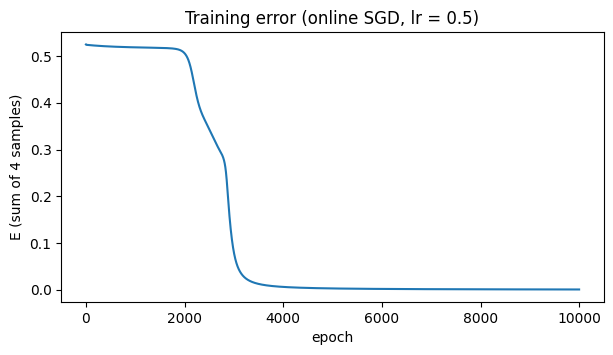

In [22]:
plt.figure(figsize=(7, 3.5))                 # 그래프 크기 (가로 7, 세로 3.5)
plt.plot(loss_history)                       # 에포크별 오차 합
plt.xlabel("epoch")                          # x축: 반복 횟수
plt.ylabel("E (sum of 4 samples)")           # y축: 오차 합 (영문: Colab 한글 깨짐 방지)
plt.title("Training error (online SGD, lr = 0.5)")  # 제목
plt.show()                                   # 그리기

🔍 약 2000 에포크까지는 오차가 거의 줄지 않다가(제자리걸음), 2000~3000 사이에 두 번에 걸쳐 **갑자기** 뚝 떨어집니다. 신경망이 XOR 규칙을 "깨닫는" 순간입니다.

### 5-6. 신경망이 XOR 을 나누는 모습 (결정 경계)
9차시에서 직선 하나(단층 퍼셉트론)로는 XOR 을 나눌 수 없었습니다. 은닉층이 있는 신경망은 어떻게 나눌까요? 색은 출력 o 입니다 (파랑 = 0, 빨강 = 1).
(그림을 그리는 코드입니다 — 결과 그림만 보셔도 됩니다)

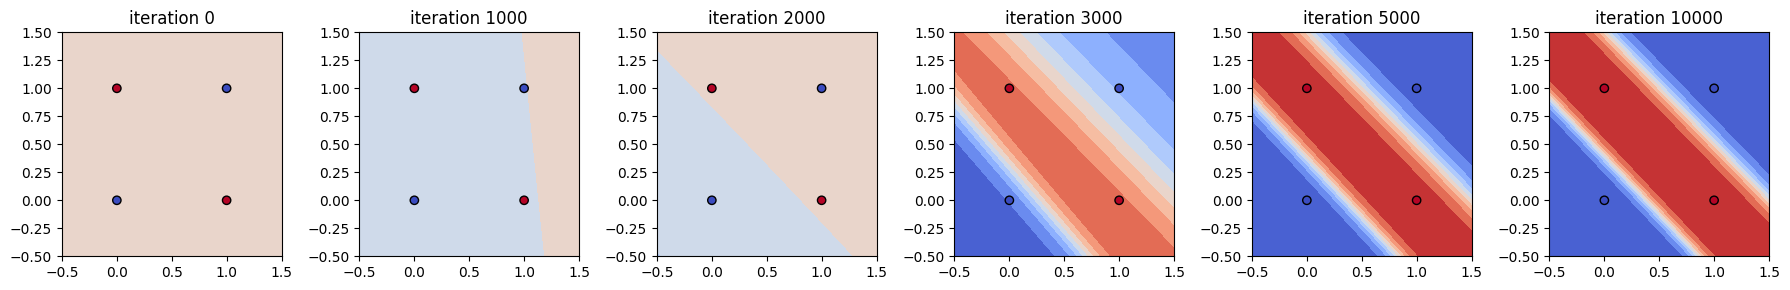

In [23]:
g = torch.linspace(-0.5, 1.5, 101)             # -0.5 ~ 1.5 를 101칸으로
gx, gy = torch.meshgrid(g, g, indexing="xy")   # 격자 좌표 (x1, x2)
grid = torch.stack([gx.flatten(), gy.flatten()], dim=1)  # 📐 (10201, 2) 입력 묶음
levels = torch.linspace(0, 1, 11).tolist()     # 색 구간 0.0, 0.1, …, 1.0 (고정)
fig, axes = plt.subplots(1, 6, figsize=(18, 3))  # 그림 6개를 가로로
for ax, k in zip(axes, [0, 1000, 2000, 3000, 5000, 10000]):  # 시점마다
    m = make_model()                           # 모델을 만들어
    m.load_state_dict(snap_w[k])               # 그 시점의 가중치 넣기
    with torch.no_grad():                      # 계산기 모드
        z = m(grid).reshape(101, 101)          # 격자 전체의 출력 o
    ax.contourf(gx, gy, z, levels=levels, cmap="coolwarm")  # 출력을 색으로
    ax.scatter(X[:, 0], X[:, 1], c=T[:, 0], cmap="coolwarm", edgecolors="k")  # XOR 4점
    ax.set_title(f"iteration {k}")             # 제목: 반복 횟수
plt.tight_layout()                             # 간격 정리
plt.show()                                     # 그리기

🔍 0 회에는 전체가 0.5 근처(연한 색)입니다. 1000~2000 회에는 **직선 하나로** 나누려고 애쓰지만 실패합니다 — 9차시 단층 퍼셉트론의 한계와 같습니다. 3000 회 무렵 가운데에 **빨간 띠**가 생기며 (1,0)·(0,1) 은 빨강, (0,0)·(1,1) 은 파랑으로 나뉩니다. 은닉노드 2개가 **직선 2개**를 만들고, 출력층이 둘을 조합해 "띠"를 만든 것입니다.

**📝 1분 퀴즈** ① 학습 루프 4단계를 순서대로 말해 보세요. ② `optimizer.zero_grad()` 를 빼면?
<details><summary>정답 보기</summary>

① 순전파 `model(x)` → 오차 `loss_fn(o, t)` → 역전파 `zero_grad()` + `backward()` → 업데이트 `step()`
② 이전 샘플의 기울기가 계속 더해져(누적) 엉뚱한 방향으로 학습합니다.
</details>

---
## 6. 실험실 — 바꿔 보면 무엇이 달라질까?  🎬 EP5

### 6-1. ✋ 먼저 예측해 보세요
4개 샘플을 **한꺼번에(배치)** 계산해서 에포크마다 **1번만** 업데이트하면 어떻게 될까요?
(가) 더 빨리 학습한다 (나) 똑같이 학습한다 (다) 학습이 안 된다

In [24]:
model_b = make_model()                       # 같은 초기 가중치로 새 모델
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.5)  # 같은 학습률 0.5
for epoch in range(10000):                   # 같은 10000 에포크
    loss = loss_fn(model_b(X), T)            # 4개 샘플을 '한꺼번에' 순전파 → 오차 합
    opt_b.zero_grad()                        # 기울기 지우기
    loss.backward()                          # 역전파: 4개 샘플의 기울기가 '합쳐짐'
    opt_b.step()                             # 업데이트는 에포크당 1번
with torch.no_grad():                        # 계산기 모드
    print("배치 학습 후 출력:", model_b(X).flatten())  # 네 개 모두 0.5 근처 → 제자리!

배치 학습 후 출력: tensor([0.4999, 0.5002, 0.4998, 0.5001])


정답은 **(다)** 입니다 — 적어도 이 초기값 · 2-2-1 신경망 · SGD 조건에서는요. 왜 그럴까요? 처음 위치에서 샘플별 기울기를 구해 보면 —

In [25]:
model_c = make_model()                         # 처음 가중치
for i in range(4):                             # 샘플마다
    model_c.zero_grad()                        # 기울기 지우고
    loss_fn(model_c(X[i:i+1]), T[i:i+1]).backward()  # 그 샘플 하나의 기울기 계산
    g9 = model_c.output.bias.grad.item()       # w9 의 기울기 꺼내기
    print(f"샘플 {i+1} 의 ∂E/∂w9 = {g9:+.4f}")  # + 이면 w9 를 줄이라는 뜻
model_c.zero_grad()                            # 이번엔 4개를 한꺼번에
loss_fn(model_c(X), T).backward()              # 배치 기울기 = 4개 기울기의 합
g9 = model_c.output.bias.grad.item()           # 합쳐진 w9 기울기
print(f"4개 합친 ∂E/∂w9 = {g9:+.4f}  ← 확 줄었다!")  # 서로 상쇄됨

샘플 1 의 ∂E/∂w9 = +0.1297
샘플 2 의 ∂E/∂w9 = -0.1200
샘플 3 의 ∂E/∂w9 = -0.1199
샘플 4 의 ∂E/∂w9 = +0.1297
4개 합친 ∂E/∂w9 = +0.0195  ← 확 줄었다!


🔍 샘플 1·4 는 "w9 를 줄여라(+)", 샘플 2·3 은 "w9 를 늘려라(−)" 라고 서로 반대로 말합니다. 한꺼번에 더하면 서로 **상쇄**되어 크기가 샘플 하나일 때의 약 1/7 로 줄고, 네 출력을 모두 0.5 로 맞추는 '타협점' 쪽으로만 끌려가 거기서 멈춥니다. 한 샘플씩 업데이트하면 매번 조금씩 다른 방향으로 흔들리며 이 '제자리'를 빠져나옵니다.
> 💡 10차시 5.4.3 Batch size — 1회 업데이트에 사용하는 데이터 수가 **학습 결과까지** 바꿀 수 있습니다.

### 6-2. 학습률 α 바꾸기 (0.1 · 0.5 · 2.0)
⏸ 약 10~20초 걸립니다.

lr = 0.1: 출력 tensor([0.4997, 0.4998, 0.5000, 0.5001])


lr = 0.5: 출력 tensor([0.0469, 0.9638, 0.9631, 0.0328])


lr = 2.0: 출력 tensor([0.7160, 0.7157, 0.7156, 0.0127])


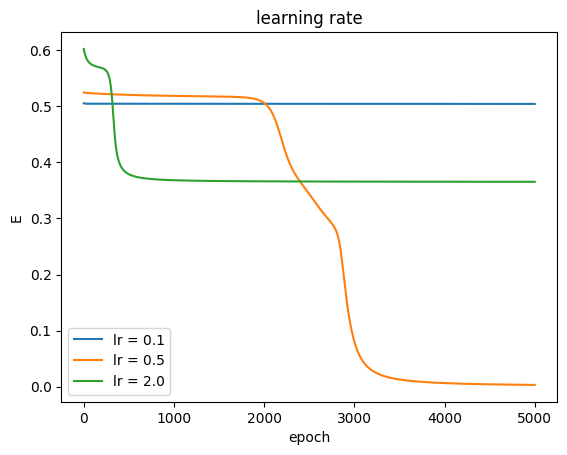

In [26]:
for lr in [0.1, 0.5, 2.0]:                     # 학습률 3가지
    m = make_model()                           # 매번 같은 초기 가중치로 새로 시작
    opt = torch.optim.SGD(m.parameters(), lr=lr)  # 이번 학습률로 경사하강법
    hist = []                                  # 오차 기록
    for epoch in range(5000):                  # 5000 에포크
        outputs, total = train_one_epoch(m, opt)  # 1 에포크 학습
        hist.append(total)                     # 오차 합 기록
    plt.plot(hist, label=f"lr = {lr}")         # 오차 곡선 그리기
    with torch.no_grad():                      # 계산기 모드
        print(f"lr = {lr}: 출력", m(X).flatten())  # 5000 에포크 후 출력
plt.xlabel("epoch"); plt.ylabel("E"); plt.legend(); plt.title("learning rate")  # 꾸미기
plt.show()                                     # 그리기

🔍 **결과 읽는 법**
- **0.1 (너무 작음)** — 5000 에포크가 지나도 0.5 근처: 너무 조심스러워 제자리걸음
- **0.5 (적당함)** — 약 3000 에포크 만에 정답
- **2.0 (너무 큼)** — 성큼성큼 움직이다 엉뚱한 골짜기(**지역 최솟값**)에 빠져 세 출력이 0.7 근처에서 멈춤

> 💡 9차시: α 가 작으면 촘촘하지만 느리고, 크면 빠르지만 지나치거나 엉뚱한 곳에 머물 수 있습니다.

### 6-3. 초기 가중치가 랜덤이라면?
지금까지는 10차시 그림의 가중치로 시작했습니다. 보통은 PyTorch가 **랜덤**으로 정해 줍니다. `torch.manual_seed(번호)` 로 랜덤의 '씨앗'을 바꿔 가며 시작점을 바꿔 봅시다. ⏸ 약 10~20초

In [27]:
for seed in range(5):                          # 랜덤 씨앗 0~4
    torch.manual_seed(seed)                    # 씨앗 고정 → 같은 번호면 같은 랜덤 값
    m = XORNet()                               # 랜덤 초기 가중치로 새 모델
    opt = torch.optim.SGD(m.parameters(), lr=0.5)  # 같은 조건 (α = 0.5)
    for epoch in range(3000):                  # 3000 에포크 온라인 학습
        train_one_epoch(m, opt)                # (결과는 아래에서 확인)
    with torch.no_grad():                      # 계산기 모드
        out = m(X).flatten()                   # 4개 샘플 출력
    pred = (out > 0.5).float()                 # 0.5 보다 크면 1, 아니면 0 으로 판정
    ok = torch.equal(pred, T.flatten())        # 4개 모두 정답과 같은가?
    print(f"seed {seed}: 출력 {out} →", "성공 👍" if ok else "🔸 실패(정상 결과)")

seed 0: 출력 tensor([0.5136, 0.5066, 0.9461, 0.0429]) → 🔸 실패(정상 결과)


seed 1: 출력 tensor([0.0518, 0.9499, 0.9497, 0.0581]) → 성공 👍


seed 2: 출력 tensor([0.0734, 0.9441, 0.9437, 0.0488]) → 성공 👍


seed 3: 출력 tensor([0.0524, 0.9591, 0.9590, 0.0368]) → 성공 👍


seed 4: 출력 tensor([0.0921, 0.9317, 0.9309, 0.0575]) → 성공 👍


🔍 같은 신경망 · 같은 학습률인데도 **시작점에 따라 실패**할 수 있습니다. (실패한 경우는 3만 에포크까지 돌려도 그대로였습니다) 은닉노드가 2개뿐인 작은 신경망은 '골짜기(지역 최솟값)'에 빠지기 쉽습니다. 그래서 실제로는 은닉노드를 넉넉히 두고 더 좋은 최적화 방법을 씁니다 ↓
(성공/실패는 컴퓨터나 PyTorch 버전에 따라 일부 달라질 수 있습니다.)

### 6-4. (선택 · 심화) 요즘 방식으로 풀면?
은닉노드 8개 + `Tanh` 활성화 + 이진 교차엔트로피(`BCELoss`, 9차시) + `Adam` 최적화기를 쓰면 훨씬 빨리 풉니다.
> 💡 `nn.Sequential(층1, 층2, …)` : 층을 순서대로 이어 붙이는 간단한 설계도입니다.

In [28]:
torch.manual_seed(0)                           # 재현을 위해 씨앗 고정
net = nn.Sequential(nn.Linear(2, 8), nn.Tanh(),     # 입력 2 → 은닉 8 (Tanh)
                    nn.Linear(8, 1), nn.Sigmoid())  # 은닉 8 → 출력 1 (Sigmoid)
bce = nn.BCELoss()                             # 이진 교차엔트로피 (9차시 분류 비용함수)
opt = torch.optim.Adam(net.parameters(), lr=0.05)  # Adam: 똑똑한 경사하강법
first = None                                   # 처음으로 4개 모두 맞힌 업데이트 번호
for step in range(1, 301):                     # 배치로 300번만! (은닉 8개 + Adam 덕분)
    loss = bce(net(X), T)                      # 1️⃣ 순전파 + 2️⃣ 오차
    opt.zero_grad()                            # 3️⃣ 기울기 지우기
    loss.backward()                            # 3️⃣ 역전파
    opt.step()                                 # 4️⃣ 업데이트
    if first is None and torch.equal((net(X) > 0.5).float(), T):  # 4개 모두 맞으면
        first = step                           # 그 번호를 기록
with torch.no_grad():                          # 계산기 모드
    print("출력:", net(X).flatten())            # 거의 0, 1, 1, 0
print("처음 4개 모두 맞힌 업데이트 번호:", first)    # 10차시 방식은 약 1만 1천 번!
check("Adam 모델 출력", net(X).detach(), T, tol=0.05)  # ✅

출력: tensor([0.0005, 0.9997, 0.9995, 0.0007])
처음 4개 모두 맞힌 업데이트 번호: 12
✅ Adam 모델 출력: 최대 차이 0.000714 (허용 0.05)


🔍 똑같은 '4단계' 학습 루프인데, 부품(층 · 비용함수 · 최적화기)만 바꿔도 업데이트 약 1만 1천 번(10차시 방식) → 십여 번으로 줄어듭니다. **학습 루프의 뼈대는 그대로**라는 점이 핵심입니다. 다음 시간 FashionMNIST(이미지 6만 장)도 이 뼈대로 학습합니다.

### 6-5. 🏆 도전 과제
1. **AND / OR 문제** — `T` 만 바꿔서 학습시켜 보세요. (힌트: 샘플 순서는 11, 10, 01, 00)
2. **은닉노드 1개** — `XORNet` 의 은닉노드를 1개로 줄이면(`nn.Linear(2, 1)`, `nn.Linear(1, 1)`) XOR 을 풀 수 있을까요? 결과와 이유를 적어 보세요. (힌트: 9차시 단층 퍼셉트론 · `make_model()` 은 2-2-1 가중치를 복사하므로 쓰지 말고, 고친 설계도로 바로 `XORNet()` 을 만드세요)
3. **경주** — 6-4 에서 학습률(`lr`)이나 은닉노드 수를 바꾸면 "처음 4개 모두 맞힌 업데이트 번호"가 어떻게 달라지나요? 가장 빠른 조합을 찾아보세요.

---
## 7. 핵심 요약

### 이론 ↔ 코드 대응표 (XOR 판)
| 10차시 이론 | PyTorch 코드 |
|---|---|
| 입력 · 정답 표 | `X = torch.tensor(...)`, `T = torch.tensor(...)` |
| 가중치 w1~w9 | `nn.Linear(2, 2)`, `nn.Linear(2, 1)` → `model.parameters()` |
| 순전파 h = σ(Wx + b), o = σ(Wh + b) | `o = model(x)` (내부에서 `forward`) |
| 비용함수 E = ½(t − o)² | `loss = loss_fn(o, t)` |
| 오류역전파 ∂E/∂w | `loss.backward()` |
| 경사하강법 w ← w − α·∂E/∂w | `optimizer.step()` |
| 학습률 α = 0.5 | `lr=0.5` |
| 에포크(반복) | `for epoch in range(10000):` |
| 온라인 vs 배치 | `X[i:i+1]` 한 샘플씩 vs `X` 한꺼번에 |

### 학습 루프 4단계 (꼭 기억!)
```python
o = model(x)            # 1️⃣ 순전파
loss = loss_fn(o, t)    # 2️⃣ 오차 계산
optimizer.zero_grad()   # 3️⃣ 역전파: 기울기 지우고
loss.backward()         #           기울기 계산
optimizer.step()        # 4️⃣ 가중치 업데이트
```

### ⚠️ 자주 하는 실수 5가지
1. `optimizer.zero_grad()` 를 빼먹음 → 기울기가 누적되어 엉뚱하게 학습
2. 정답을 `(4,)` 모양으로 만듦 → `(4, 1)` 출력과 계산할 때 `(4, 4)` 로 늘어나는 조용한 오류
3. `1.` 대신 `1` 로 씀 → 정수(int) 텐서는 신경망 계산 · 미분에서 오류
4. 가중치를 직접 고칠 때 `with torch.no_grad():` 를 빼먹음 → 오류
5. 학습률이 너무 작거나 큼 → 제자리걸음 또는 지역 최솟값 · 발산

### 10차시 노트의 XOR 코드와 무엇이 다른가요?
10차시 노트의 코드(입력에 1 열 추가, 은닉노드 5개, ReLU, BCE, 학습률 0.02)는 "**작동하는 예시**"이고, 오늘 노트북은 그림과 **똑같은 조건**(2-2-1, 시그모이드, ½(t−o)², 학습률 0.5, 한 샘플씩)으로 "**손계산을 재현**"하는 것이 목적입니다. 둘 다 같은 4단계 학습 루프를 씁니다.

### 다음 시간 (Part 2) 예고
데이터가 4개가 아니라 **이미지 6만 장**이라면? → `Dataset` · `DataLoader` 로 묶어서, 10가지 옷 종류를 분류하는 FashionMNIST 신경망을 만듭니다.